<a href="https://colab.research.google.com/github/fboldt/aulas-am-bsi/blob/main/aula24a_perceptron_learning_algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [30]:
import numpy as np

def create_dataset(n=20):
  X = np.random.rand(n, 2)
  y = np.array(X[:,0]>X[:,1], dtype=int)*2-1
  return X, y

X, y = create_dataset(20)
print(X)
print(y)

[[0.91487802 0.47445871]
 [0.03582506 0.73392912]
 [0.28201471 0.70429081]
 [0.77795508 0.45659101]
 [0.04849959 0.99937432]
 [0.96522649 0.82222092]
 [0.96125967 0.61108773]
 [0.24273812 0.97654109]
 [0.22995848 0.0270908 ]
 [0.57079534 0.5980576 ]
 [0.73163322 0.05556767]
 [0.09941003 0.76534806]
 [0.63817867 0.98125212]
 [0.6815966  0.56756959]
 [0.25020846 0.43471631]
 [0.9596328  0.03467878]
 [0.33610216 0.38455556]
 [0.81391061 0.57134582]
 [0.51647829 0.3712658 ]
 [0.93172595 0.71310463]]
[ 1 -1 -1  1 -1  1  1 -1  1 -1  1 -1 -1  1 -1  1 -1  1  1  1]


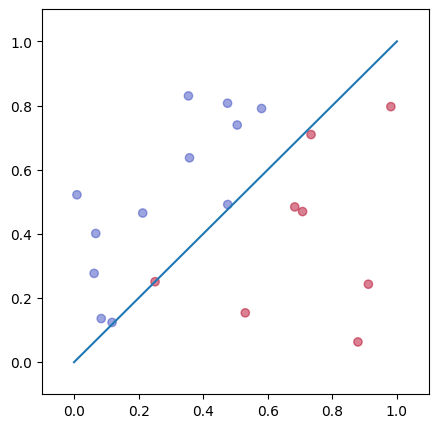

In [48]:
from matplotlib import pyplot as plt

def plot_dataset(X, y):
  plt.figure(figsize=(5,5))
  plt.scatter(X[:,0], X[:,1], c=y, cmap="coolwarm", alpha=0.5)
  plt.xlim(-0.1, 1.1)
  plt.ylim(-0.1, 1.1)

X, y = create_dataset(20)
plot_dataset(X, y)
plt.plot([0,1], [0,1])
plt.show()

In [27]:
X = np.random.rand(5, 2)
coefs = np.array([1, -1])
y = X @ coefs
print(X)
print(y)

[[0.27522047 0.28473979]
 [0.89179222 0.43728456]
 [0.99156831 0.39080412]
 [0.60913184 0.56521083]
 [0.83907046 0.95318033]]
[-0.00951931  0.45450766  0.60076419  0.04392102 -0.11410988]


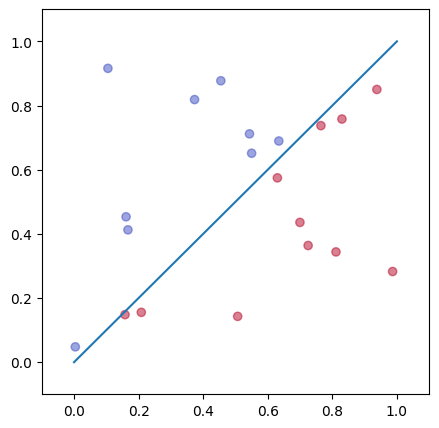

In [51]:
def create_dataset(n=20):
  X = np.random.rand(n, 2)
  coefs = np.array([1, -1])
  y = X @ coefs
  y = np.array(y>0, dtype=int)*2-1
  return X, y

X, y = create_dataset(20)
plot_dataset(X, y)
plt.plot([0,1], [0,1])
plt.show()

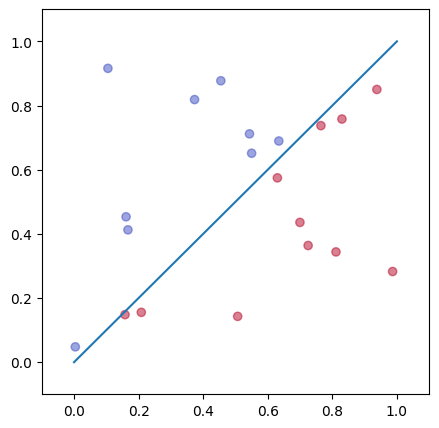

In [52]:
def plot_hyperplan(coefs):
  xs = np.array([0,1])
  ys = -(coefs[0]*xs)/coefs[1]
  plt.plot(xs, ys)

plot_dataset(X, y)
plot_hyperplan([1, -1])
plt.show()

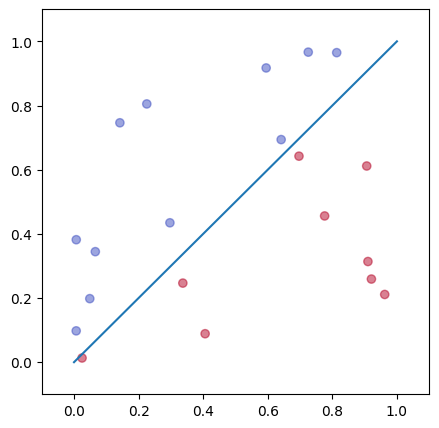

In [56]:
def create_dataset(n=20, coefs=np.array([1, -1])):
  X = np.random.rand(n, 2)
  y = X @ coefs
  y = np.array(y>0, dtype=int)*2-1
  return X, y

coefs=np.array([1, -1])
X, y = create_dataset(20, coefs)
plot_dataset(X, y)
plot_hyperplan(coefs)
plt.show()

In [57]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import accuracy_score

class CheatingClassifier(BaseEstimator, ClassifierMixin):
  def __init__(self, coefs):
    self.coefs = coefs

  def fit(self, X, y):
    return self

  def predict(self, X):
    logits = X @ self.coefs
    y_pred = np.array(logits>0, dtype=int)*2-1
    return y_pred

clf = CheatingClassifier(coefs)
y_pred = clf.predict(X)
print(accuracy_score(y, y_pred))

1.0


In [77]:
class PLA(BaseEstimator, ClassifierMixin):
  def __init__(self, max_iter=10):
    self.max_iter = max_iter

  def fit(self, X, y):
    self.coefs = np.zeros(X.shape[1])
    # PLA - Percptron Learning Algorithm (without bias)
    for _ in range(self.max_iter):
      cost = 0
      idx = np.random.permutation(X.shape[0])
      for i in idx:
        logits = X[i] @ self.coefs
        y_pred = np.array(logits>0, dtype=int)*2-1
        error = y[i] - y_pred
        if error != 0:
          self.coefs += error * X[i]
          cost += error**2
      if cost == 0:
        break
    return self

  def predict(self, X):
    logits = X @ self.coefs
    y_pred = np.array(logits>0, dtype=int)*2-1
    return y_pred

clf = PLA(max_iter=10)
clf.fit(X, y)
print(clf.coefs)
y_pred = clf.predict(X)
print(accuracy_score(y, y_pred))

[ 3.03027029 -2.80928333]
1.0


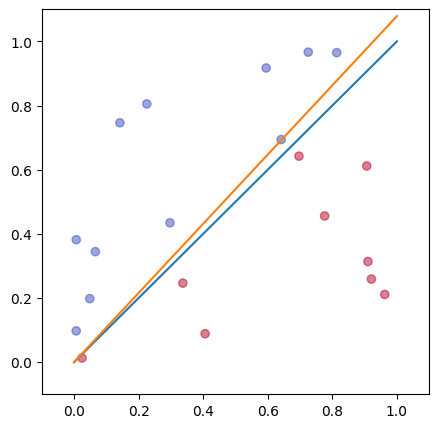

In [78]:
plot_dataset(X, y)
plot_hyperplan(coefs)
plot_hyperplan(clf.coefs)
plt.show()

0.94


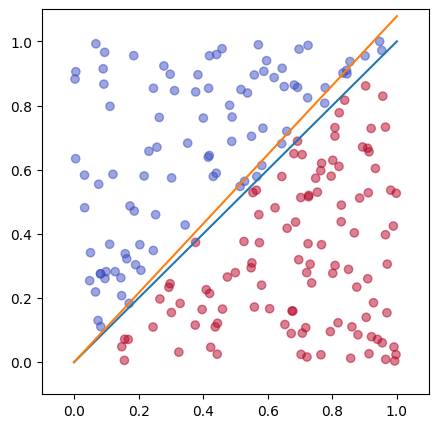

In [79]:
X_test, y_test = create_dataset(200)
print(accuracy_score(y_test, clf.predict(X_test)))
plot_dataset(X_test, y_test)
plot_hyperplan(coefs)
plot_hyperplan(clf.coefs)
plt.show()